# Bank Marketing: will the customer subscribe to a term deposit?

**Problem:** a bank phones customers to sell a term deposit. Only about 12% say yes, so calling everyone wastes time.
We predict the probability of "yes" from information known *before* the call, so the bank can call the most likely customers first.

**Data:** UCI Bank Marketing, `bank-full.csv` .

**Metric:** ROC AUC (classes are imbalanced).

**Plan:** 1) clean the data, 2) EDA and feature importance, 3) train four models (logistic regression, decision tree, random forest, XGBoost), 4) tune each one, 5) pick the best and test it, 6) move the final code to `train.py`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score, mutual_info_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb

%matplotlib inline

## 1. Load and clean the data

In [2]:
df = pd.read_csv('data/bank-full.csv', sep=';')
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
# consistent column names
df.columns = df.columns.str.lower().str.replace(' ', '_')

# 'duration' (call length) is only known AFTER the call, so using it would be data leakage.
df = df.drop(columns=['duration'])

# target: yes -> 1, no -> 0
df['y'] = (df['y'] == 'yes').astype(int)

print('shape:', df.shape)
print('duplicated rows:', df.duplicated().sum())
df.dtypes

shape: (45211, 16)
duplicated rows: 16


age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
campaign     int64
pdays        int64
previous     int64
poutcome       str
y            int64
dtype: object

## 2. Exploratory data analysis

In [4]:
print('Missing values per column:')
print(df.isnull().sum())

Missing values per column:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64


In [5]:


print()
print("'unknown' values per categorical column (they stay as their own category):")
cat_cols_all = df.select_dtypes(exclude='number').columns
print((df[cat_cols_all] == 'unknown').sum())


'unknown' values per categorical column (they stay as their own category):
job            288
marital          0
education     1857
default          0
housing          0
loan             0
contact      13020
month            0
poutcome     36959
dtype: int64


In [6]:
categorical = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
numerical = ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

df[numerical].describe().T

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


### Target variable

y
0    39922
1     5289
Name: count, dtype: int64

y
0    0.883
1    0.117
Name: proportion, dtype: float64


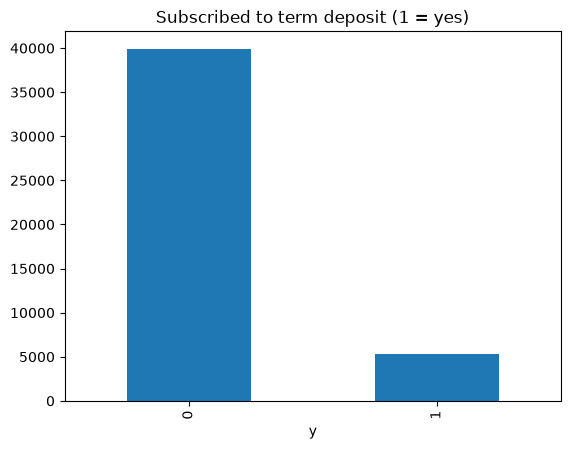

In [7]:
print(df.y.value_counts())
print()
print(df.y.value_counts(normalize=True).round(3))

df.y.value_counts().plot(kind='bar', title='Subscribed to term deposit (1 = yes)')
plt.show()

The target is imbalanced (about 12% positives), which is why we use ROC AUC instead of accuracy.

### Numerical features

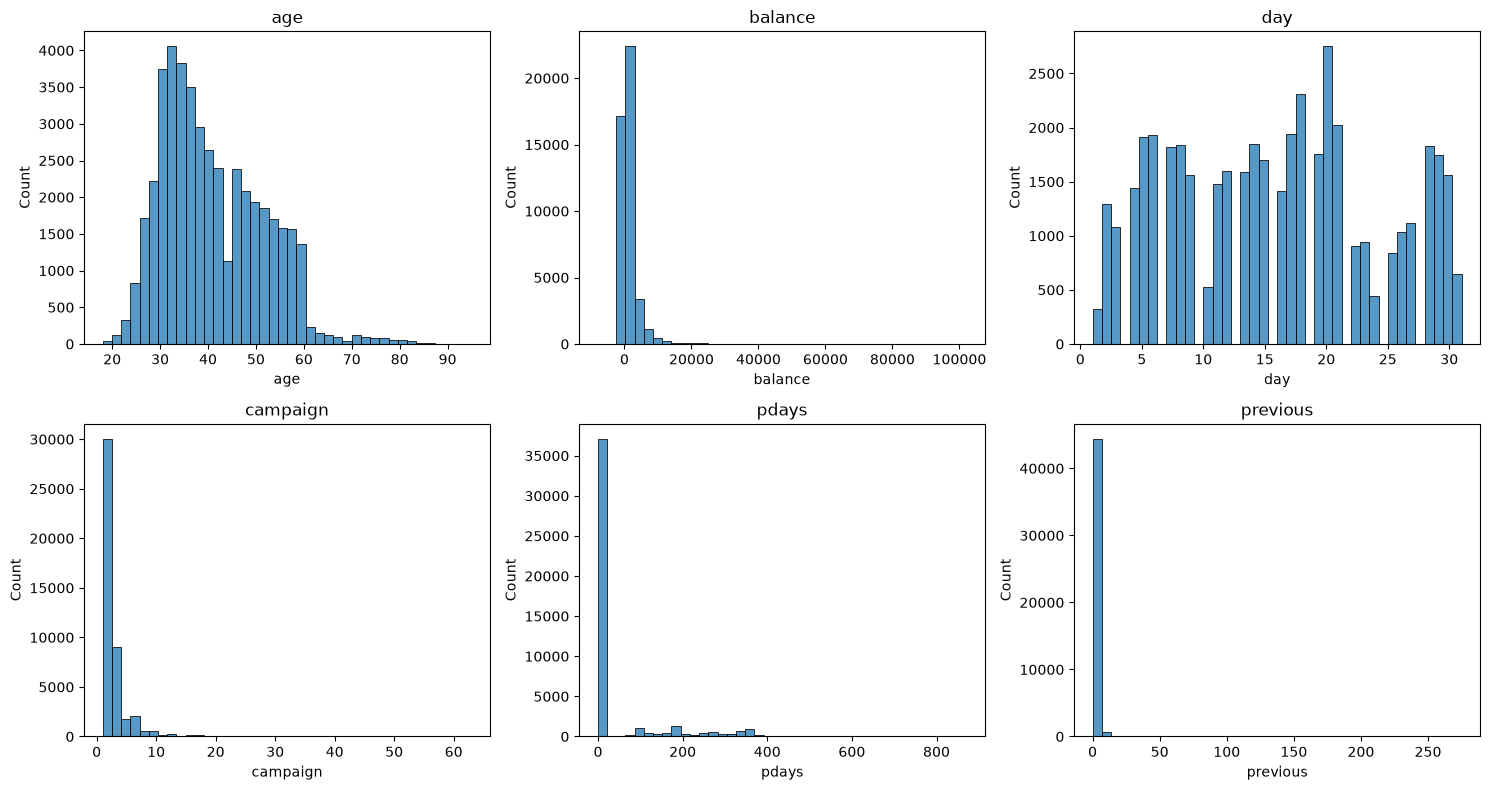

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), numerical):
    sns.histplot(df[col], bins=40, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [9]:
# balance, campaign, previous are heavily skewed: look at the high quantiles
df[['balance', 'campaign', 'previous', 'pdays']].quantile([0.5, 0.9, 0.99, 1.0])

,balance,campaign,previous,pdays
0.50,448.0,2.0,0.0,-1.0
0.90,3574.0,5.0,2.0,185.0
0.99,13164.9,16.0,8.9,370.0
1.00,102127.0,63.0,275.0,871.0


`pdays = -1` means the customer was never contacted in an earlier campaign. Tree-based models handle this value fine.

### Categorical features: subscription rate per category

In [10]:
global_rate = df.y.mean()
print(f'Global subscription rate: {global_rate:.3f}')

for col in categorical:
    stats = df.groupby(col).y.agg(['mean', 'count']).sort_values('mean', ascending=False)
    stats['diff'] = stats['mean'] - global_rate
    print(f'--- {col} ---')
    print(stats.round(3))
    print()

Global subscription rate: 0.117
--- job ---
                mean  count   diff
job                               
student        0.287    938  0.170
retired        0.228   2264  0.111
unemployed     0.155   1303  0.038
management     0.138   9458  0.021
admin.         0.122   5171  0.005
self-employed  0.118   1579  0.001
unknown        0.118    288  0.001
technician     0.111   7597 -0.006
services       0.089   4154 -0.028
housemaid      0.088   1240 -0.029
entrepreneur   0.083   1487 -0.034
blue-collar    0.073   9732 -0.044

--- marital ---
           mean  count   diff
marital                      
single    0.149  12790  0.033
divorced  0.119   5207  0.002
married   0.101  27214 -0.016

--- education ---
            mean  count   diff
education                     
tertiary   0.150  13301  0.033
unknown    0.136   1857  0.019
secondary  0.106  23202 -0.011
primary    0.086   6851 -0.031

--- default ---
          mean  count   diff
default                     
no       0.118  443

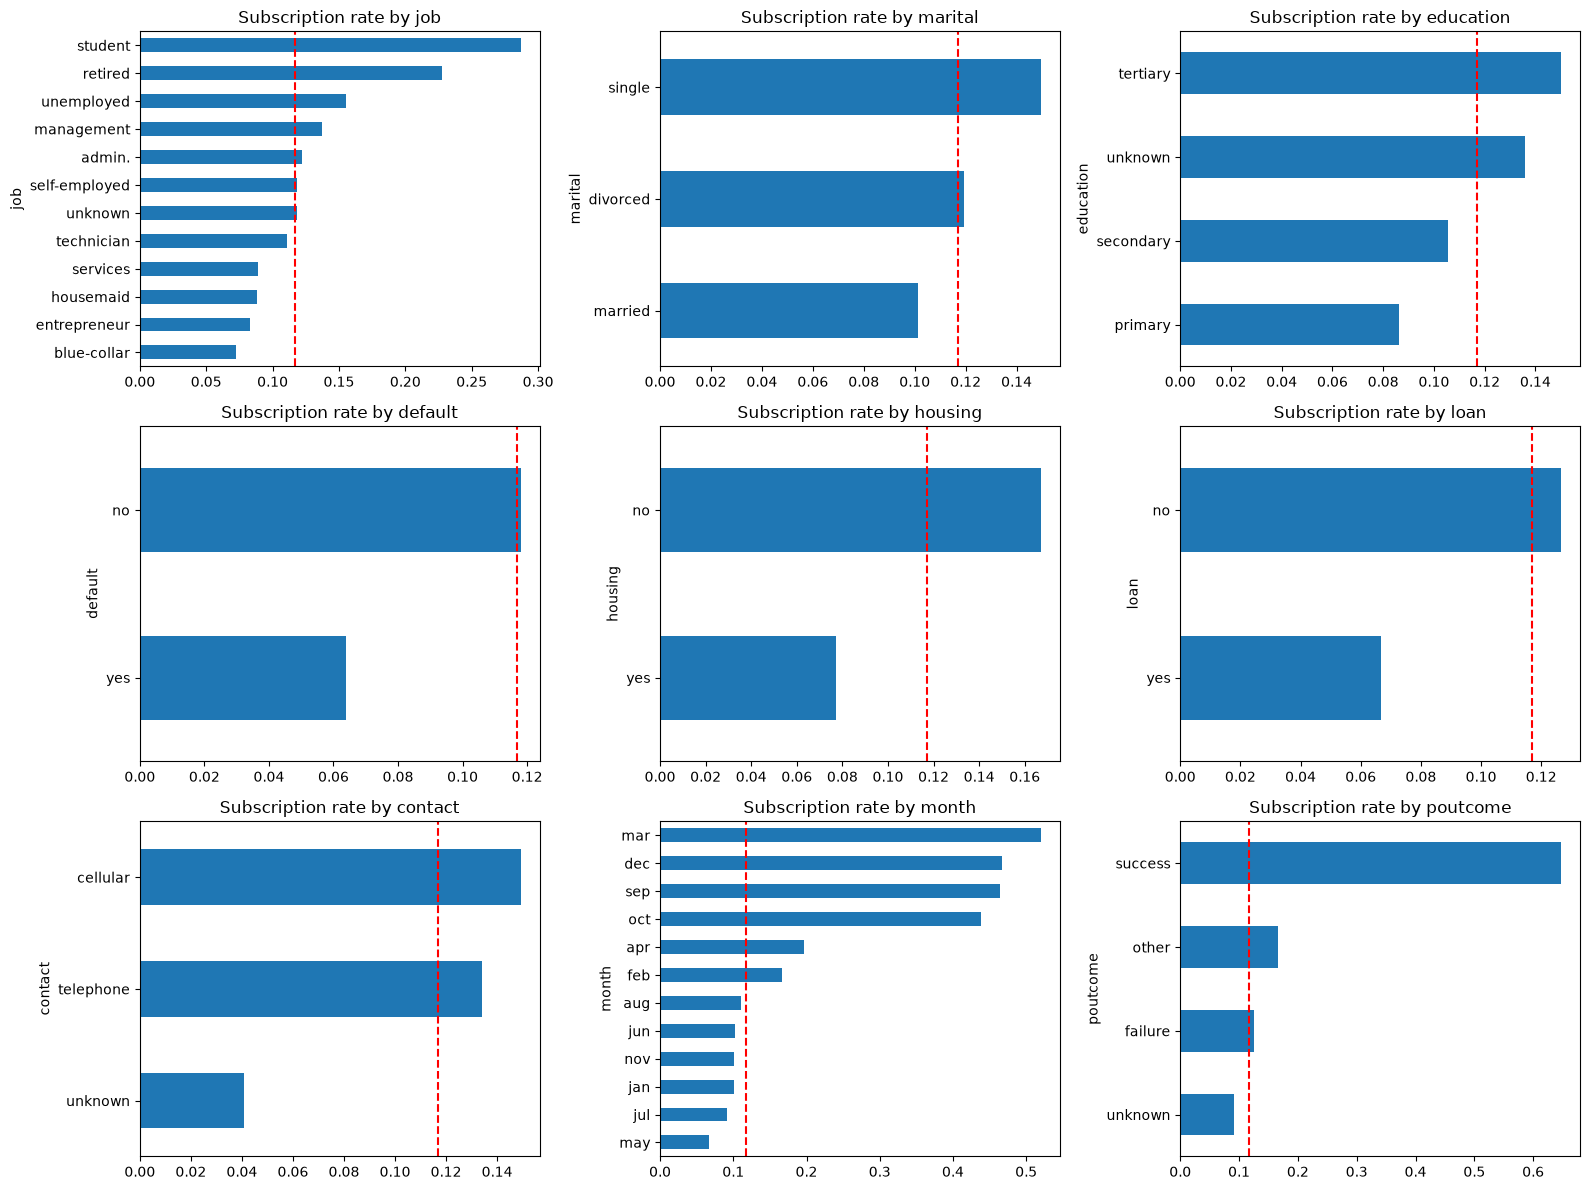

In [11]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, col in zip(axes.ravel(), categorical):
    df.groupby(col).y.mean().sort_values().plot(kind='barh', ax=ax)
    ax.axvline(global_rate, color='red', linestyle='--')
    ax.set_title(f'Subscription rate by {col}')
plt.tight_layout()
plt.show()

## 3. Train / validation / test split (60 / 20 / 20, stratified)

In [12]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1, stratify=df.y)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1, stratify=df_full_train.y)

df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train, y_val, y_test = df_train.y.values, df_val.y.values, df_test.y.values
print(len(df_train), len(df_val), len(df_test))

27126 9042 9043


## 4. Feature importance

In [13]:
# Categorical: mutual information with the target (higher = more informative)
def mi_score(col):
    return mutual_info_score(col, df_full_train.y)

mi = df_full_train[categorical].apply(mi_score).sort_values(ascending=False)
mi.to_frame('mutual_info')

,mutual_info
poutcome,0.029948
month,0.024383
contact,0.013206
housing,0.009091
job,0.008462
loan,0.002645
education,0.002549
marital,0.001914
default,0.000342


In [14]:
# Numerical: correlation with the target
df_full_train[numerical].corrwith(df_full_train.y).sort_values(ascending=False).to_frame('correlation')

,correlation
pdays,0.106851
previous,0.088729
balance,0.048057
age,0.021976
day,-0.030527
campaign,-0.072407


Feature	Correlation suggests
pdays	+0.107	Customers contacted in an earlier campaign are somewhat more likely to subscribe
previous	+0.089	More earlier contacts goes with slightly higher subscription
balance	+0.048	Customers with a higher balance are slightly more likely to say yes
age	+0.022	Almost no straight-line relationship
day	-0.031	Day of the month hardly matters
campaign	-0.072	More calls in this campaign goes with a lower chance of yes

In [26]:
df_full_train.groupby(pd.cut(df_full_train.age, [17, 25, 35, 45, 55, 65, 100])).y.mean()

age
(17, 25]     0.236792
(25, 35]     0.121098
(35, 45]     0.093705
(45, 55]     0.094179
(55, 65]     0.140875
(65, 100]    0.410000
Name: y, dtype: float64

In [27]:
pd.cut(df_full_train.age, [17, 25, 35, 45, 55, 65, 100]).value_counts().sort_index()

age
(17, 25]      1060
(25, 35]     12428
(35, 45]     11120
(45, 55]      7645
(55, 65]      3315
(65, 100]      600
Name: count, dtype: int64

Age has almost no straight-line correlation, but grouping shows a U-shape: the youngest and oldest customers subscribe most.

The oldest group is small (600 customers), so its rate is less certain.

The model should capture this, so trees may do better than plain logistic regression on age.

## 5. Helper functions

In [15]:
features = categorical + numerical

def prepare(df_a, df_b):
    dv = DictVectorizer(sparse=False)
    X_a = dv.fit_transform(df_a[features].to_dict(orient='records'))
    X_b = dv.transform(df_b[features].to_dict(orient='records'))
    return dv, X_a, X_b

dv, X_train, X_val = prepare(df_train, df_val)
print(X_train.shape)

results = []   # (model name, parameters, validation AUC)

(27126, 50)


In [28]:
dv.get_feature_names_out()

array(['age', 'balance', 'campaign', 'contact=cellular',
       'contact=telephone', 'contact=unknown', 'day', 'default=no',
       'default=yes', 'education=primary', 'education=secondary',
       'education=tertiary', 'education=unknown', 'housing=no',
       'housing=yes', 'job=admin.', 'job=blue-collar', 'job=entrepreneur',
       'job=housemaid', 'job=management', 'job=retired',
       'job=self-employed', 'job=services', 'job=student',
       'job=technician', 'job=unemployed', 'job=unknown', 'loan=no',
       'loan=yes', 'marital=divorced', 'marital=married',
       'marital=single', 'month=apr', 'month=aug', 'month=dec',
       'month=feb', 'month=jan', 'month=jul', 'month=jun', 'month=mar',
       'month=may', 'month=nov', 'month=oct', 'month=sep', 'pdays',
       'poutcome=failure', 'poutcome=other', 'poutcome=success',
       'poutcome=unknown', 'previous'], dtype=object)

In [29]:
for i, name in enumerate(dv.get_feature_names_out(), start=1):
    print(i, name)

1 age
2 balance
3 campaign
4 contact=cellular
5 contact=telephone
6 contact=unknown
7 day
8 default=no
9 default=yes
10 education=primary
11 education=secondary
12 education=tertiary
13 education=unknown
14 housing=no
15 housing=yes
16 job=admin.
17 job=blue-collar
18 job=entrepreneur
19 job=housemaid
20 job=management
21 job=retired
22 job=self-employed
23 job=services
24 job=student
25 job=technician
26 job=unemployed
27 job=unknown
28 loan=no
29 loan=yes
30 marital=divorced
31 marital=married
32 marital=single
33 month=apr
34 month=aug
35 month=dec
36 month=feb
37 month=jan
38 month=jul
39 month=jun
40 month=mar
41 month=may
42 month=nov
43 month=oct
44 month=sep
45 pdays
46 poutcome=failure
47 poutcome=other
48 poutcome=success
49 poutcome=unknown
50 previous


## 6. Model 1: Logistic regression

In [16]:
for C in [0.01, 0.1, 1, 10]:
    model = LogisticRegression(C=C, solver='liblinear', max_iter=1000, random_state=1)
    model.fit(X_train, y_train)
    auc = roc_auc_score(y_val, model.predict_proba(X_val)[:, 1])
    results.append(('logistic_regression', {'C': C}, auc))
    print(f'C={C:<5} AUC={auc:.4f}')

C=0.01  AUC=0.7677
C=0.1   AUC=0.7679
C=1     AUC=0.7665
C=10    AUC=0.7655


## 7. Model 2: Decision tree

In [30]:
for depth in [3, 5, 7, 10, 15]:
    for leaf in [5, 20, 50, 100]:
        model = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=1)
        model.fit(X_train, y_train)
        auc = roc_auc_score(y_val, model.predict_proba(X_val)[:, 1])
        results.append(('decision_tree', {'max_depth': depth, 'min_samples_leaf': leaf}, auc))
        print(f'max_depth={depth:<3} min_samples_leaf={leaf:<4} AUC={auc:.4f}')

max_depth=3   min_samples_leaf=5    AUC=0.6247
max_depth=3   min_samples_leaf=20   AUC=0.6254
max_depth=3   min_samples_leaf=50   AUC=0.6254
max_depth=3   min_samples_leaf=100  AUC=0.6254
max_depth=5   min_samples_leaf=5    AUC=0.7016
max_depth=5   min_samples_leaf=20   AUC=0.7041
max_depth=5   min_samples_leaf=50   AUC=0.7041
max_depth=5   min_samples_leaf=100  AUC=0.7041
max_depth=7   min_samples_leaf=5    AUC=0.7062
max_depth=7   min_samples_leaf=20   AUC=0.7160
max_depth=7   min_samples_leaf=50   AUC=0.7205
max_depth=7   min_samples_leaf=100  AUC=0.7203
max_depth=10  min_samples_leaf=5    AUC=0.7129
max_depth=10  min_samples_leaf=20   AUC=0.7346
max_depth=10  min_samples_leaf=50   AUC=0.7399
max_depth=10  min_samples_leaf=100  AUC=0.7461
max_depth=15  min_samples_leaf=5    AUC=0.7022
max_depth=15  min_samples_leaf=20   AUC=0.7662
max_depth=15  min_samples_leaf=50   AUC=0.7704
max_depth=15  min_samples_leaf=100  AUC=0.7767


## 8. Model 3: Random forest

In [32]:
for n in [100, 200]:
    for depth in [5, 10, 15]:
        for leaf in [1, 5, 10]:
            model = RandomForestClassifier(n_estimators=n, max_depth=depth, min_samples_leaf=leaf,
                                           n_jobs=-1, random_state=1)
            model.fit(X_train, y_train)
            auc = roc_auc_score(y_val, model.predict_proba(X_val)[:, 1])
            results.append(('random_forest', {'n_estimators': n, 'max_depth': depth, 'min_samples_leaf': leaf}, auc))
            print(f'n={n:<4} max_depth={depth:<3} min_samples_leaf={leaf:<3} AUC={auc:.4f}')

n=100  max_depth=5   min_samples_leaf=1   AUC=0.7733
n=100  max_depth=5   min_samples_leaf=5   AUC=0.7730
n=100  max_depth=5   min_samples_leaf=10  AUC=0.7733
n=100  max_depth=10  min_samples_leaf=1   AUC=0.7933
n=100  max_depth=10  min_samples_leaf=5   AUC=0.7944
n=100  max_depth=10  min_samples_leaf=10  AUC=0.7946
n=100  max_depth=15  min_samples_leaf=1   AUC=0.7978
n=100  max_depth=15  min_samples_leaf=5   AUC=0.7978
n=100  max_depth=15  min_samples_leaf=10  AUC=0.7988
n=200  max_depth=5   min_samples_leaf=1   AUC=0.7754
n=200  max_depth=5   min_samples_leaf=5   AUC=0.7746
n=200  max_depth=5   min_samples_leaf=10  AUC=0.7749
n=200  max_depth=10  min_samples_leaf=1   AUC=0.7947
n=200  max_depth=10  min_samples_leaf=5   AUC=0.7962
n=200  max_depth=10  min_samples_leaf=10  AUC=0.7949
n=200  max_depth=15  min_samples_leaf=1   AUC=0.7975
n=200  max_depth=15  min_samples_leaf=5   AUC=0.7987
n=200  max_depth=15  min_samples_leaf=10  AUC=0.7987


In [33]:
for depth in [20, 25, None]:
    model = RandomForestClassifier(n_estimators=100, max_depth=depth, min_samples_leaf=10,
                                   n_jobs=-1, random_state=1)
    model.fit(X_train, y_train)
    auc = roc_auc_score(y_val, model.predict_proba(X_val)[:, 1])
    results.append(('random_forest', {'n_estimators': 100, 'max_depth': depth, 'min_samples_leaf': 10}, auc))
    print(f'max_depth={str(depth):<5} AUC={auc:.4f}')

max_depth=20    AUC=0.7988
max_depth=25    AUC=0.7975
max_depth=None  AUC=0.7977


Going deeper than 15 doesn’t help. The score is the same at 20 and slightly lower beyond that, which is a sign the trees are starting to fit noise.

## 9. Model 4: XGBoost

In [19]:
feature_names = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=feature_names)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=feature_names)

for eta in [0.05, 0.1, 0.3]:
    for depth in [3, 6]:
        for mcw in [1, 10]:
            params = {'eta': eta, 'max_depth': depth, 'min_child_weight': mcw,
                      'objective': 'binary:logistic', 'eval_metric': 'auc', 'nthread': 4, 'seed': 1}
            model = xgb.train(params, dtrain, num_boost_round=200)
            auc = roc_auc_score(y_val, model.predict(dval))
            results.append(('xgboost', {'eta': eta, 'max_depth': depth, 'min_child_weight': mcw, 'rounds': 200}, auc))
            print(f'eta={eta:<5} max_depth={depth} min_child_weight={mcw:<3} AUC={auc:.4f}')

eta=0.05  max_depth=3 min_child_weight=1   AUC=0.8021
eta=0.05  max_depth=3 min_child_weight=10  AUC=0.8008
eta=0.05  max_depth=6 min_child_weight=1   AUC=0.8025
eta=0.05  max_depth=6 min_child_weight=10  AUC=0.8026
eta=0.1   max_depth=3 min_child_weight=1   AUC=0.8042
eta=0.1   max_depth=3 min_child_weight=10  AUC=0.8038
eta=0.1   max_depth=6 min_child_weight=1   AUC=0.7984
eta=0.1   max_depth=6 min_child_weight=10  AUC=0.8005
eta=0.3   max_depth=3 min_child_weight=1   AUC=0.8027
eta=0.3   max_depth=3 min_child_weight=10  AUC=0.8017
eta=0.3   max_depth=6 min_child_weight=1   AUC=0.7770
eta=0.3   max_depth=6 min_child_weight=10  AUC=0.7813


## 10. Compare the models

In [35]:
res = pd.DataFrame(results, columns=['model', 'params', 'val_auc'])
best_per_model = res.sort_values('val_auc', ascending=False).groupby('model').head(1).sort_values('val_auc', ascending=False)
best_per_model.reset_index(drop=True)

,model,params,val_auc
0,xgboost,"{'eta': 0.1, 'max_depth': 3, 'min_child_weight...",0.804153
1,random_forest,"{'n_estimators': 100, 'max_depth': 15, 'min_sa...",0.798844
2,decision_tree,"{'max_depth': 15, 'min_samples_leaf': 100}",0.776650
3,logistic_regression,{'C': 0.1},0.767939


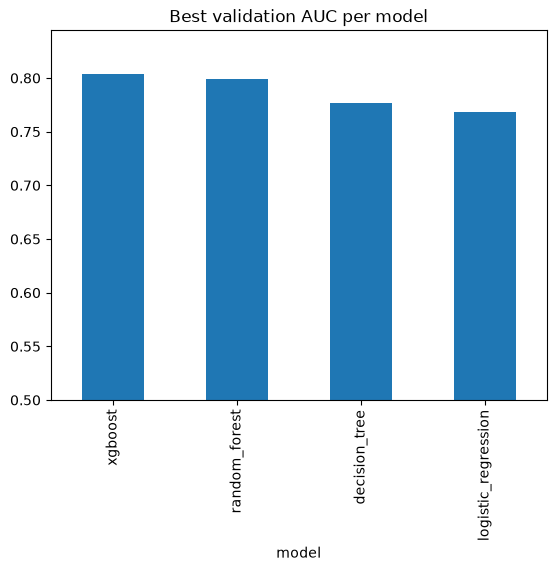

In [21]:
best_per_model.plot(x='model', y='val_auc', kind='bar', legend=False, ylim=(0.5, None),
                    title='Best validation AUC per model')
plt.show()

**Winner: XGBoost** (eta=0.1, max_depth=3, min_child_weight=10, 200 rounds), validation AUC 0.804.

| Model | Best parameters | Validation AUC |
|---|---|---|
| Logistic regression | C=0.1 | 0.768 |
| Decision tree | max_depth= 15, min_samples_leaf=100 | 0.776650 |
| Random forest | n_estimators=100, max_depth=15, min_samples_leaf=10 | 0.799 |
| XGBoost | eta=0.1, max_depth=3, min_child_weight=10 | 0.804 |

XGBoost scored highest, but only about 0.005 above the random forest, so the two are close.
With a high learning rate (eta=0.3) and deeper trees (max_depth=6) it overfitted and fell to 0.777,
so shallow trees with a moderate learning rate worked best.
These parameters are used in `train.py`.

In [36]:
best = res.sort_values('val_auc', ascending=False).iloc[0]
print('Best model :', best['model'])
print('Parameters :', best['params'])
print(f"Validation AUC: {best['val_auc']:.4f}")

Best model : xgboost
Parameters : {'eta': 0.1, 'max_depth': 3, 'min_child_weight': 1, 'rounds': 200}
Validation AUC: 0.8042


## 11. Final model: cross-validation and test set

In [39]:

xgb_params = {'eta': 0.1, 'max_depth': 3, 'min_child_weight': 1,
              'objective': 'binary:logistic', 'eval_metric': 'auc', 'nthread': 4, 'seed': 1}
num_rounds = 200

def train_xgb(df_a, y_a):
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(df_a[features].to_dict(orient='records'))
    d = xgb.DMatrix(X, label=y_a, feature_names=list(dv.get_feature_names_out()))
    return dv, xgb.train(xgb_params, d, num_boost_round=num_rounds)

def predict_xgb(df_b, dv, model):
    X = dv.transform(df_b[features].to_dict(orient='records'))
    return model.predict(xgb.DMatrix(X, feature_names=list(dv.get_feature_names_out())))

# 5-fold cross-validation on the full training part
scores = []
for tr_idx, va_idx in KFold(5, shuffle=True, random_state=1).split(df_full_train):
    tr, va = df_full_train.iloc[tr_idx], df_full_train.iloc[va_idx]
    dv_cv, m_cv = train_xgb(tr, tr.y.values)
    scores.append(roc_auc_score(va.y, predict_xgb(va, dv_cv, m_cv)))
print('CV AUC: %.3f +- %.3f' % (np.mean(scores), np.std(scores)))

CV AUC: 0.799 +- 0.003


In [40]:
dv_final, model_final = train_xgb(df_full_train, df_full_train.y.values)
test_auc = roc_auc_score(y_test, predict_xgb(df_test, dv_final, model_final))
print(f'Test AUC: {test_auc:.4f}')

Test AUC: 0.8080


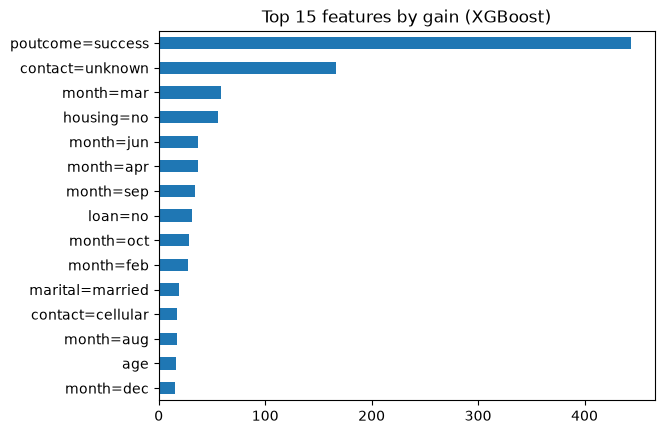

In [42]:
# Which features does the final model use most? (gain)
imp = pd.Series(model_final.get_score(importance_type='gain')).sort_values(ascending=False).head(15)
imp.sort_values().plot(kind='barh', title='Top 15 features by gain (XGBoost)')
plt.show()

## 12. Conclusion

- Four model families were compared with parameter tuning on a validation set; the best one is confirmed by 5-fold cross-validation and a held-out test set (fill in the final numbers).
- Most informative features (fill in from the feature-importance cells above): ...
- Dropping `duration` makes the score lower than in many online examples, but this is the honest score: the call length is unknown before calling.
- The final training code lives in `train.py` and the service in `predict.py`.